# 实验：时间数据的可视化

In [1]:
import base64
import csv
from pathlib import Path

import numpy as np
from IPython.display import IFrame
import matplotlib.pyplot as plt

from pyecharts import options as opts
from pyecharts.charts import Bar, Line, Page, Polar
from pyecharts.globals import CurrentConfig, ThemeType

plt.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
CurrentConfig.ONLINE_HOST = "https://fastly.jsdelivr.net/gh/pyecharts/pyecharts-assets@master/assets/v5/"


def show_chart(filename, height=520):
    html = Path(filename).read_text(encoding="utf-8")
    data = base64.b64encode(html.encode("utf-8")).decode("ascii")
    return IFrame(src=f"data:text/html;base64,{data}", width="100%", height=height)


In [2]:
# 案例1 梯形图
postage_years = [
    "1995", "1996", "1997", "1998", "1999", "2000", "2001",
    "2002", "2003", "2004", "2005", "2006", "2007", "2008", "2009",
]
postage = [
    0.32, 0.32, 0.32, 0.32, 0.33, 0.33, 0.34,
    0.37, 0.37, 0.37, 0.37, 0.39, 0.41, 0.42, 0.44,
]

(
    Line()
    .add_xaxis(xaxis_data=postage_years)
    .add_yaxis(
        series_name="美国邮费",
        y_axis=postage,
        symbol="emptyCircle",
        is_step=True,
    )
    .render("case1.html")
)


show_chart("case1.html")

In [3]:
# 案例2 折线图
(
    Line()
    .add_xaxis(xaxis_data=postage_years)
    .add_yaxis(
        series_name="美国邮费",
        y_axis=postage,
        symbol="emptyCircle",
        is_step=False,
    )
    .set_global_opts(
        yaxis_opts=opts.AxisOpts(min_=0.3, max_=0.45)
    )
    .render("case2.html")
)


show_chart("case2.html")

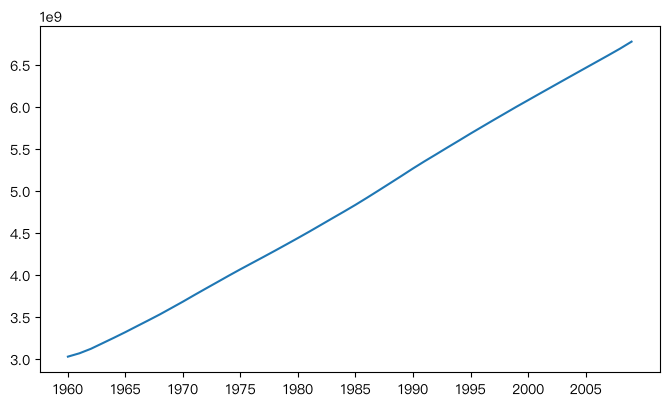

In [4]:
# 案例3 世界人口折线图
world_years = []
world_pop = []
with open("world-population.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        world_years.append(int(row[0]))
        world_pop.append(int(row[1]))

plt.figure(figsize=(8, 4.5))
plt.plot(world_years, world_pop)
plt.xticks(np.arange(1960, 2010, 5))
plt.yticks(np.arange(3e9, 7e9, 5e8))
plt.show()


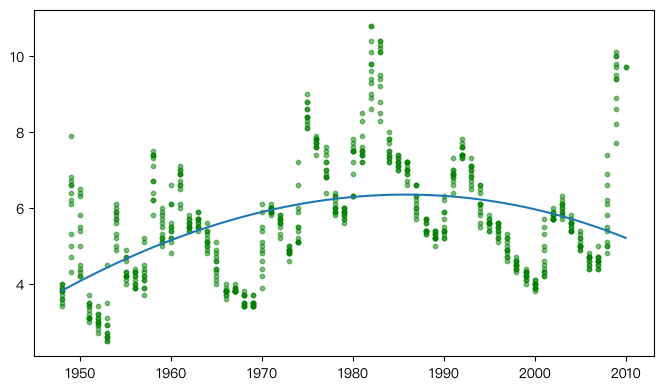

In [5]:
# 案例4 拟合曲线
unemp_years = []
unemp_rates = []
with open("unemployment-rate-1948-2010.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        unemp_years.append(int(row[1]))
        unemp_rates.append(float(row[3]))

plt.figure(figsize=(8, 4.5))
plt.scatter(unemp_years, unemp_rates, s=10, c="g", marker="o", alpha=0.5)

poly = np.polyfit(unemp_years, unemp_rates, deg=3)
plt.plot(unemp_years, np.polyval(poly, unemp_years))
plt.show()


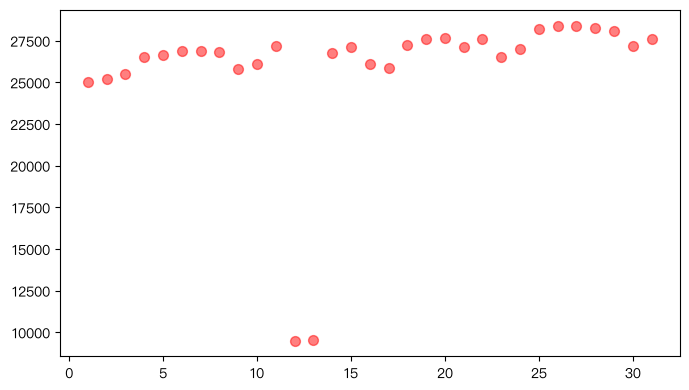

In [6]:
# 案例5 散点图
subs = []
with open("subscribers.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        subs.append(int(row[1]))

subs_x = list(range(1, len(subs) + 1))

plt.figure(figsize=(8, 4.5))
plt.scatter(subs_x, subs, s=50, c="r", marker="o", alpha=0.5)
plt.show()


In [7]:
# 案例6 柱形图
hotdog_years = []
hotdog_dogs = []
with open("hot-dog-contest-winners.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        hotdog_years.append(row[0])
        hotdog_dogs.append(float(row[2]))

(
    Bar()
    .add_xaxis(hotdog_years)
    .add_yaxis("热狗比赛", hotdog_dogs)
    .render("case6.html")
)


show_chart("case6.html")

In [8]:
# 案例7 堆叠柱形图
places = []
with open("hot-dog-places.csv", newline="", encoding="utf-8-sig") as f:
    places = list(csv.reader(f))

places_years = places[0]
first = [float(v) for v in places[1]]
second = [float(v) for v in places[2]]
third = [float(v) for v in places[3]]

(
    Bar()
    .add_xaxis(places_years)
    .add_yaxis("第一名", first, stack="all")
    .add_yaxis("第二名", second, stack="all")
    .add_yaxis("第三名", third, stack="all")
    .render("case7.html")
)


show_chart("case7.html")

In [9]:
# 实验数据
datax = []
with open("hot-dog-places.csv", newline="", encoding="utf-8-sig") as f:
    reader = csv.reader(f)
    for row in reader:
        datax.append(row)

radius = datax[0]
y1 = [float(v) for v in datax[1]]
y2 = [float(v) for v in datax[2]]
y3 = [float(v) for v in datax[3]]


In [10]:
# 实验 实例1：角度轴表示时间
a = (
    Polar(init_opts=opts.InitOpts(theme=ThemeType.CHALK))
    .set_global_opts(title_opts=opts.TitleOpts(title="极坐标-堆叠柱状图实例1"))
    .add_schema(angleaxis_opts=opts.AngleAxisOpts(data=radius))
    .add("A", y1, type_="bar", stack="1")
    .add("B", y2, type_="bar", stack="1")
    .add("C", y3, type_="bar", stack="1")
)
a.render("a.html")


show_chart("a.html")

In [11]:
# 实验 实例2：半径轴表示时间
b = (
    Polar(init_opts=opts.InitOpts(theme=ThemeType.CHALK))
    .set_global_opts(title_opts=opts.TitleOpts(title="极坐标-堆叠柱状图实例2"))
    .add_schema(radiusaxis_opts=opts.RadiusAxisOpts(data=radius))
    .add("A", y1, type_="bar", stack="1")
    .add("B", y2, type_="bar", stack="1")
    .add("C", y3, type_="bar", stack="1")
)
b.render("b.html")


show_chart("b.html")

In [12]:
# 实验 两张图合并
page = Page().add(a).add(b)
page.render("render.html")
show_chart("render.html", 1050)
